In [1]:
# 加载环境变量量
from dotenv import load_dotenv

load_dotenv()  # take environment variables from .env.

True

In [2]:
#定义工具
from langchain.tools import tool
@tool
def get_weather(location: str) -> str:
    """获取指定城市的天气信息"""
    # 这里可以调用实际的天气API来获取数据
    return f"{location}的天气是晴天，温度25摄氏度。"

In [3]:
from langchain.agents import create_agent

agent = create_agent(
    "deepseek-chat",
    tools = [get_weather]
)

In [5]:
# 4.调用Agent
print("正在调用大模型...")
response = agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": "杭州的天气怎么样？"
        }
    ]
})

正在调用大模型...


In [7]:
print(response)

{'messages': [HumanMessage(content='杭州的天气怎么样？', additional_kwargs={}, response_metadata={}, id='0ffa572a-6caa-4b59-bb6b-82cfad89112e'), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 38, 'prompt_tokens': 269, 'total_tokens': 307, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 269}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': 'ab8e061f-e497-4ee3-baf7-2d7704efb2ce', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1bf7e-8486-7161-b926-5dd0b5903115-0', tool_calls=[{'name': 'get_weather', 'args': {'location': '杭州'}, 'id': 'call_00_E4jMDYH0nSItQh0FG9zd6697', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 269, 'outp

In [8]:
for message in response["messages"]:
    print(message.model_dump_json(indent=2))
    print("----------------------------------------")

{
  "content": "杭州的天气怎么样？",
  "additional_kwargs": {},
  "response_metadata": {},
  "type": "human",
  "name": null,
  "id": "0ffa572a-6caa-4b59-bb6b-82cfad89112e"
}
----------------------------------------
{
  "content": "",
  "additional_kwargs": {
    "refusal": null
  },
  "response_metadata": {
    "token_usage": {
      "completion_tokens": 38,
      "prompt_tokens": 269,
      "total_tokens": 307,
      "completion_tokens_details": null,
      "prompt_tokens_details": {
        "audio_tokens": null,
        "cache_write_tokens": null,
        "cached_tokens": 0,
        "image_tokens": null,
        "text_tokens": null
      },
      "prompt_cache_hit_tokens": 0,
      "prompt_cache_miss_tokens": 269
    },
    "model_provider": "deepseek",
    "model_name": "deepseek-flash",
    "system_fingerprint": "bc19ba97cbe016479903222bb1578db6",
    "id": "ab8e061f-e497-4ee3-baf7-2d7704efb2ce",
    "finish_reason": "tool_calls",
    "logprobs": null
  },
  "type": "ai",
  "name": null,
 

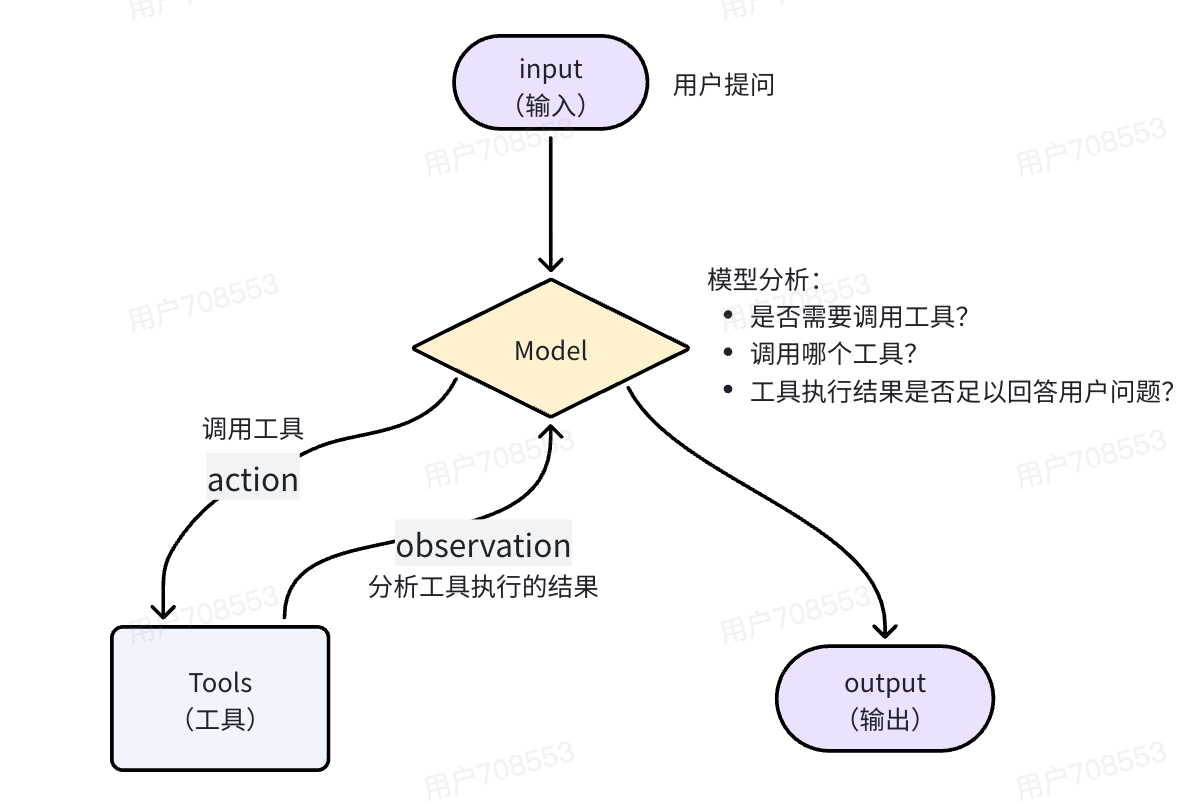